# JDSearch — LightGBM for Personalised Product Re-ranking

## Model building and training with selected features

This notebook trains one **LightGBM LambdaRank** model using **23 candidate-level inputs**:
- 7 historical personalisation features;
- 7 current-query matching features (including corrected product-name token overlap);
- 7 additional historical, product, and candidate-slate features;
- 2 precomputed training-derived engagement features.

Training uses session-disjoint training and validation data, and the main selection metric is graded **NDCG@10** with relevance gains `[0,1,3,7]`. Binary NDCG@10 is also reported for evaluation compatibility. The test set is not used during tuning.

**Feature refinement:** We improved two existing query-matching features. `name_query_match` was revised to count overlapping query and product-name tokens, while `query_match_count` was recalculated accordingly. The remaining selected features were reused from the existing feature-engineering outputs.

**Reproducibility:** Original input files remain read-only. The corrected features, models, predictions and evaluation results are saved in this notebook's independent output directory, without modifying the original feature files or previous model directories. Query matching uses anonymised tokens without assuming their semantic meanings.

## 1. Setup and Google Drive

In [ ]:
# Run this cell once in Colab. Restart the runtime if Colab requests it.
%pip -q install "lightgbm>=4.0,<5" "pyarrow>=14" "pandas>=2" "duckdb>=1.1,<2"

In [ ]:
import os, gc, json, random, time, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import lightgbm as lgb
import duckdb
import matplotlib.pyplot as plt
from IPython.display import display

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab. Set PROJECT_DIR to the local JDSearch folder.')

Mounted at /content/drive


## 2. Input paths and independent output directory

The processed candidate features, query-feature checkpoint and raw query text are read-only. All new files are written into a dedicated directory. The raw query source is used **only** to compute query–product token overlap.


In [ ]:
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

PROJECT_DIR = Path('/content/drive/MyDrive/BT4222 Final/JDSearch')
PROCESSED_DIR = PROJECT_DIR / 'processed'
BASE_FEATURE_DIR = PROCESSED_DIR / 'lgbm_features_all'  # Read-only input
CANONICAL_SPLIT = PROCESSED_DIR / 'user_split.csv'    # Read-only input
RAW_USER_FILE = PROJECT_DIR / 'Raw Data' / 'user_behavior_data.txt'  # Read-only input

# Resolve the query-matching checkpoint without writing personal names in the notebook.
checkpoint_matches = sorted(PROCESSED_DIR.glob('*candidate_features_checkpoint*.parquet'))
if len(checkpoint_matches) != 1:
    raise FileNotFoundError(
        f'Expected exactly one candidate-feature checkpoint in {PROCESSED_DIR}; '
        f'found {len(checkpoint_matches)}. Verify the input filename.'
    )
QUERY_FEATURE_CHECKPOINT = checkpoint_matches[0]

OUTPUT_ROOT = PROJECT_DIR / 'model_artifacts' / 'lightgbm_popularity_query_search'
FAST_DEV_MODE = False
TRAIN_SESSION_FRACTION = 0.08 if FAST_DEV_MODE else 1.0
VAL_SESSION_FRACTION = 0.20 if FAST_DEV_MODE else 1.0
RUN_NAME = 'dev' if FAST_DEV_MODE else 'full'
RUN_DIR = OUTPUT_ROOT / RUN_NAME
MERGED_DIR = OUTPUT_ROOT / 'cached_merged_features' / 'selected_features'
QUERY_LOOKUP = OUTPUT_ROOT / 'cached_merged_features' / 'session_queries.parquet'
FORCE_REBUILD_CACHE = False
FINALIZE_TEST = True  # Switch to True ONLY after validation-based model selection is final.

def safe_output_path(path):
    p = Path(path).resolve()
    root = OUTPUT_ROOT.resolve()
    if p != root and root not in p.parents:
        raise ValueError(f'Blocked write outside the dedicated output folder: {p}')
    return p

assert not OUTPUT_ROOT.resolve().is_relative_to(PROCESSED_DIR.resolve())
for path in (OUTPUT_ROOT, RUN_DIR, MERGED_DIR):
    safe_output_path(path).mkdir(parents=True, exist_ok=True)
for source in (BASE_FEATURE_DIR, CANONICAL_SPLIT, RAW_USER_FILE, QUERY_FEATURE_CHECKPOINT):
    if not source.exists():
        raise FileNotFoundError(f'Missing required input: {source}')

print('Read-only feature input:', BASE_FEATURE_DIR)
print('Results output directory:', RUN_DIR)
print('Independent feature cache:', MERGED_DIR)
print('LightGBM version:', lgb.__version__)


Read-only feature input: /content/drive/MyDrive/BT4222 Final/JDSearch/processed/lgbm_features_all
Results output directory: /content/drive/MyDrive/BT4222 Final/JDSearch/model_artifacts/lightgbm_popularity_query_search/full
Independent feature cache: /content/drive/MyDrive/BT4222 Final/JDSearch/model_artifacts/lightgbm_popularity_query_search/cached_merged_features/selected_features
LightGBM version: 4.6.0


### File locations

```text
JDSearch/
├── processed/                                      [READ ONLY]
│   ├── lgbm_features_all/                          candidate features, with out-of-fold CTR priors
│   ├── *candidate_features_checkpoint*.parquet      matching indicators and product metadata
│   └── user_split.csv                              canonical session split
├── Raw Data/
│   └── user_behavior_data.txt                      anonymised current query tokens [READ ONLY]
└── model_artifacts/
    └── lightgbm_popularity_query_search/           [NEW OUTPUT DIRECTORY]
        ├── cached_merged_features/
        │   ├── session_queries.parquet
        │   └── selected_features/
        │       ├── train.parquet
        │       ├── val.parquet
        |       ├── test.parquet
        |       ├── train_groups.npy
        |       ├── val_groups.npy
        |       ├── test_groups.npy
        |       └── feature_list.json
        |       
        ├── dev/
        └── full/
            ├── best_model.txt
            ├── val_predictions.parquet
            ├── train_predictions.parquet
            ├── test_predictions.parquet
            ├── train_groups.npy
            ├── val_groups.npy
            ├── test_groups.npy
            ├── tuning_results.csv
            ├── feature_importance.csv
            ├── feature_quality.csv
            ├── feature_names.json
            ├── comparable_validation_metrics.json
            ├── evaluation_handoff.json
            └── training_manifest.json
```

No files in the previous model-output directories are modified.


## 3. Select the 23 model input features

The selected features combine existing personalisation, current-query matching and product/history context features with two precomputed historical engagement features: `item_ctr_train` and `cate3_ctr_train`.

These engagement features were generated during the upstream feature-engineering stage using five-fold out-of-fold statistics for training observations and training-derived statistics for validation and test observations. This notebook incorporates the existing features without recalculating them from interaction labels.

**Corrected query feature:** `name_query_match` now counts the number of **distinct query tokens** also appearing in the candidate product's anonymised name (rather than requiring an entire name to match one token). `query_match_count` is recomputed as the number of matching product fields, with the name field counted as one field whenever its token overlap is positive. `name_query_match` can therefore be 0, 1, 2, ... rather than only 0 or 1.

Explicitly excluded: `position`, `item_impr_train`, and `i2v_cos_max_slate_pct`.


In [ ]:
PERSONALISATION_7 = [
    'exact_wid_last_seen_days', 'shop_share', 'shop_last_seen_days',
    'title_cos_max', 'i2v_cos_mean', 'last_i2v_cos', 'shop_aff_slate_pct'
]
QUERY_MATCH_7 = [
    'name_query_match', 'brand_name_query_match',
    'cate_name_1_query_match', 'cate_name_2_query_match',
    'cate_name_3_query_match', 'cate_name_4_query_match',
    'query_match_count',
]
CONTEXT_7 = [
    'brand_aff', 'cate3_aff', 'last_same_brand', 'last_same_cate3',
    'qhist_wid_cnt', 'title_cos_profile', 'cate3_slate_share',
]
POPULARITY_2 = ['item_ctr_train', 'cate3_ctr_train']
FEATURES = PERSONALISATION_7 + QUERY_MATCH_7 + CONTEXT_7 + POPULARITY_2
PROHIBITED_FEATURES = {'position', 'item_impr_train', 'i2v_cos_max_slate_pct'}
assert len(PERSONALISATION_7) == len(QUERY_MATCH_7) == len(CONTEXT_7) == 7
assert len(POPULARITY_2) == 2 and len(FEATURES) == len(set(FEATURES)) == 23
assert not set(FEATURES) & (PROHIBITED_FEATURES | {'session_id', 'wid', 'label', 'split'})

# Only these fields are imported from the query checkpoint. Its old name-matching
# and total-count columns are replaced with newly computed versions.
OTHER_QUERY_FIELDS = [
    'brand_name_query_match', 'cate_name_1_query_match',
    'cate_name_2_query_match', 'cate_name_3_query_match', 'cate_name_4_query_match',
]
required_base = {'session_id', 'wid', 'label'} | set(PERSONALISATION_7 + CONTEXT_7 + POPULARITY_2)
required_query = {'session_id', 'item_id', 'name'} | set(OTHER_QUERY_FIELDS)
for filename in ['train.parquet', 'val.parquet', 'test.parquet', 'train_groups.npy', 'val_groups.npy', 'test_groups.npy', 'feature_list.json']:
    assert (BASE_FEATURE_DIR / filename).is_file(), f'Missing base input: {filename}'
for split in ['train', 'val', 'test']:
    base_schema = set(pq.ParquetFile(BASE_FEATURE_DIR / f'{split}.parquet').schema_arrow.names)
    assert required_base <= base_schema, f'{split} missing base features: {required_base-base_schema}'
query_schema = set(pq.ParquetFile(QUERY_FEATURE_CHECKPOINT).schema_arrow.names)
assert required_query <= query_schema, f'Query checkpoint missing: {required_query-query_schema}'
source_feature_names = set(json.loads((BASE_FEATURE_DIR / 'feature_list.json').read_text()))
assert set(PERSONALISATION_7 + CONTEXT_7 + POPULARITY_2) <= source_feature_names

print('Number of selected features:', len(FEATURES))
display(pd.DataFrame({
    'feature': FEATURES,
    'group': (['Personalisation and historical interactions']*7
              + ['Current-query matching']*7
              + ['Additional product/history/slate context']*7
              + ['Training-only smoothed engagement priors']*2)
}))


Number of selected features: 23


,feature,group
0,exact_wid_last_seen_days,Personalisation and historical interactions
1,shop_share,Personalisation and historical interactions
2,shop_last_seen_days,Personalisation and historical interactions
3,title_cos_max,Personalisation and historical interactions
4,i2v_cos_mean,Personalisation and historical interactions
5,last_i2v_cos,Personalisation and historical interactions
6,shop_aff_slate_pct,Personalisation and historical interactions
7,name_query_match,Current-query matching
8,brand_name_query_match,Current-query matching
9,cate_name_1_query_match,Current-query matching


## 4. Build an independent candidate-feature cache

Each candidate is joined by **`(session_id, wid)`**, with one query-feature record for each candidate. Original identifiers, labels, row order and group arrays are preserved.

A read-only raw query text file supplies the current query, keyed by its original row index (`session_id`). Both product names and queries contain anonymised term IDs separated by the dataset's `\x18` delimiter. The new name overlap uses the count of distinct shared term IDs. The query-field matching count is recalculated to include the corrected name match.

**Safety checks:** reject duplicate join keys, missing query lookups, changed candidate counts, invalid ranking groups, or a corrected name feature that remains entirely zero. This experiment never modifies input datasets or previous model results.


In [ ]:
db = duckdb.connect(database=':memory:')
db.execute('SET threads = 4')
duckdb_tmp = safe_output_path(OUTPUT_ROOT / 'duckdb_tmp')
duckdb_tmp.mkdir(exist_ok=True)
db.execute("SET temp_directory = '" + str(duckdb_tmp).replace("'", "''") + "'")

def sql_path(path):
    return str(Path(path)).replace("'", "''")

def sql_ident(col):
    return '"' + col.replace('"', '""') + '"'

query_path = sql_path(QUERY_FEATURE_CHECKPOINT)
query_bad_key = db.execute(f"""
    SELECT COUNT(*) FROM read_parquet('{query_path}')
    WHERE TRY_CAST(session_id AS BIGINT) IS NULL
       OR TRY_CAST(item_id AS BIGINT) IS NULL
""").fetchone()[0]
if query_bad_key:
    raise ValueError(f'Query checkpoint has {query_bad_key:,} invalid join keys.')
query_duplicate = db.execute(f"""
    SELECT TRY_CAST(session_id AS BIGINT), TRY_CAST(item_id AS BIGINT), COUNT(*)
    FROM read_parquet('{query_path}')
    GROUP BY 1, 2 HAVING COUNT(*) > 1 LIMIT 1
""").fetchone()
if query_duplicate:
    raise ValueError(f'Duplicate query checkpoint keys: {query_duplicate}')
print('PASS: query checkpoint keys are valid and unique.')

# The original session_id is the zero-based row index in the raw user file.
# Read only the query column, not the long history arrays.
lookup_is_old = (not QUERY_LOOKUP.is_file()
                 or QUERY_LOOKUP.stat().st_mtime < RAW_USER_FILE.stat().st_mtime)
if FORCE_REBUILD_CACHE or lookup_is_old:
    print('Building a new session-to-query lookup from read-only anonymised queries...')
    raw_query = pd.read_csv(
        RAW_USER_FILE, sep='\t', usecols=['query'], dtype=str,
        low_memory=False, keep_default_na=False
    )
    raw_query.insert(0, 'session_id', np.arange(len(raw_query), dtype=np.int64))
    raw_query['query'] = raw_query['query'].fillna('').astype(str)
    tmp_lookup = safe_output_path(QUERY_LOOKUP.with_name('session_queries.working.parquet'))
    raw_query.to_parquet(tmp_lookup, index=False)
    tmp_lookup.replace(safe_output_path(QUERY_LOOKUP))
    del raw_query
    gc.collect()

lookup_path = sql_path(QUERY_LOOKUP)
lookup_schema = set(pq.ParquetFile(QUERY_LOOKUP).schema_arrow.names)
assert {'session_id','query'} <= lookup_schema
n_queries = int(pq.ParquetFile(QUERY_LOOKUP).metadata.num_rows)
max_session = db.execute(f"SELECT MAX(TRY_CAST(session_id AS BIGINT)) "
                         f"FROM read_parquet('{query_path}')").fetchone()[0]
if max_session is None or int(max_session) >= n_queries:
    raise AssertionError('Raw query rows do not align with candidate session_id values.')
print(f'PASS: {n_queries:,} source queries available for current-query matching.')


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

PASS: query checkpoint keys are valid and unique.
PASS: 173,831 source queries available for current-query matching.


In [ ]:
# Always use a dedicated cache; existing base/candidate checkpoint files are NEVER edited.
# Only the five other query-field matches are imported. The name overlap and
# query_match_count are recomputed from current-query and product-name tokens.
base_columns = PERSONALISATION_7 + CONTEXT_7 + POPULARITY_2
base_projection = ', '.join(
    f'TRY_CAST({sql_ident(f)} AS FLOAT) AS {sql_ident(f)}' for f in base_columns
)
other_query_projection = ', '.join(
    f'TRY_CAST({sql_ident(f)} AS FLOAT) AS {sql_ident(f)}'
    for f in OTHER_QUERY_FIELDS
)
other_query_select = ', '.join(
    f'COALESCE(q.{sql_ident(f)}, 0.0) AS {sql_ident(f)}'
    for f in OTHER_QUERY_FIELDS
)

# DuckDB list_intersect returns shared anonymised terms, without counting duplicates.
# Guard missing/empty query or product-name strings so empty tokens cannot be matches.
name_overlap = """
    CASE
        WHEN q.__sid IS NULL OR uq.session_id IS NULL THEN NULL
        WHEN q.__product_name IS NULL OR TRIM(q.__product_name) = ''
          OR uq.query IS NULL OR TRIM(uq.query) = '' THEN 0
        ELSE ARRAY_LENGTH(LIST_INTERSECT(
             STRING_SPLIT(q.__product_name, CHR(24)),
             STRING_SPLIT(uq.query, CHR(24))
        ))
    END
"""

# Keep a count of matched FIELDS, not a count of matched query tokens.
field_count_terms = ' + '.join(
    f'CASE WHEN COALESCE({sql_ident(f)}, 0.0) > 0 THEN 1 ELSE 0 END'
    for f in OTHER_QUERY_FIELDS
)

for sp in ['train', 'val', 'test']:
    source = BASE_FEATURE_DIR / f'{sp}.parquet'
    dest = safe_output_path(MERGED_DIR / f'{sp}.parquet')
    group_src = BASE_FEATURE_DIR / f'{sp}_groups.npy'
    group_dst = safe_output_path(MERGED_DIR / f'{sp}_groups.npy')
    source_rows = pq.ParquetFile(source).metadata.num_rows

    outdated = (not dest.is_file() or FORCE_REBUILD_CACHE
                or dest.stat().st_mtime < max(source.stat().st_mtime,
                                              QUERY_FEATURE_CHECKPOINT.stat().st_mtime,
                                              QUERY_LOOKUP.stat().st_mtime))
    if outdated:
        tmp_dest = safe_output_path(MERGED_DIR / f'{sp}.working.parquet')
        tmp_dest.unlink(missing_ok=True)
        print(f'Creating merged {sp} feature cache ({source_rows:,} rows)...')
        merge_sql = f"""
            COPY (
                WITH base AS (
                    SELECT ROW_NUMBER() OVER () AS __original_row,
                           CAST(session_id AS BIGINT) AS session_id,
                           CAST(wid AS BIGINT) AS wid,
                           CAST(label AS TINYINT) AS label,
                           {base_projection}
                    FROM read_parquet('{sql_path(source)}')
                ),
                query_features AS (
                    SELECT TRY_CAST(session_id AS BIGINT) AS __sid,
                           TRY_CAST(item_id AS BIGINT) AS __wid,
                           CAST(name AS VARCHAR) AS __product_name,
                           {other_query_projection}
                    FROM read_parquet('{query_path}')
                ),
                query_lookup AS (
                    SELECT CAST(session_id AS BIGINT) AS session_id,
                           CAST(query AS VARCHAR) AS query
                    FROM read_parquet('{lookup_path}')
                ),
                joined AS (
                    SELECT base.*, {other_query_select},
                           {name_overlap} AS name_query_match
                    FROM base LEFT JOIN query_features AS q
                      ON base.session_id = q.__sid AND base.wid = q.__wid
                    LEFT JOIN query_lookup AS uq ON base.session_id = uq.session_id
                )
                SELECT joined.* EXCLUDE (__original_row),
                       CASE WHEN name_query_match IS NULL THEN NULL ELSE
                           (CASE WHEN name_query_match > 0 THEN 1 ELSE 0 END)
                           + {field_count_terms}
                       END AS query_match_count
                FROM joined ORDER BY __original_row
            ) TO '{sql_path(tmp_dest)}' (FORMAT PARQUET, COMPRESSION ZSTD)
        """
        db.execute(merge_sql)
        if pq.ParquetFile(tmp_dest).metadata.num_rows != source_rows:
            tmp_dest.unlink(missing_ok=True)
            raise AssertionError(f'{sp}: candidate row count changed after join')
        missing = db.execute(f"""
            SELECT COUNT(*) FROM read_parquet('{sql_path(tmp_dest)}')
            WHERE name_query_match IS NULL OR query_match_count IS NULL
        """).fetchone()[0]
        if missing:
            tmp_dest.unlink(missing_ok=True)
            raise AssertionError(f'{sp}: {missing:,} unmatched candidates or missing queries.')
        tmp_dest.replace(dest)
        print('  New cache saved:', dest)
    else:
        print(f'Reusing new experiment {sp} cache.')

    assert pq.ParquetFile(dest).metadata.num_rows == source_rows
    assert {'session_id','wid','label',*FEATURES} <= set(
        pq.ParquetFile(dest).schema_arrow.names)
    assert not db.execute(f"SELECT COUNT(*) FROM read_parquet('{sql_path(dest)}') "
                          'WHERE name_query_match IS NULL OR query_match_count IS NULL').fetchone()[0]
    shutil.copy2(group_src, group_dst)
    groups = np.load(group_dst, mmap_mode='r')
    assert groups.ndim == 1 and np.all(groups > 0)
    assert int(groups.sum()) == source_rows

    name_stats = db.execute(f"""
        SELECT MAX(name_query_match),
               AVG(CASE WHEN name_query_match > 0 THEN 1.0 ELSE 0.0 END),
               AVG(name_query_match),
               MAX(item_ctr_train), MAX(cate3_ctr_train)
        FROM read_parquet('{sql_path(dest)}')
    """).fetchone()
    print(f'PASS {sp}: {len(groups):,} groups; {source_rows:,} rows; '
          f'max shared name tokens={name_stats[0]}, '
          f'name-match rate={name_stats[1]:.3%}')
    if not name_stats[0] or name_stats[0] <= 0:
        raise AssertionError(
            f'{sp}: corrected name feature is still zero for every row. '
            'Check raw query/session alignment and the product-name token separator.'
        )
    if name_stats[3] is None or name_stats[4] is None:
        raise AssertionError(f'{sp}: the two popularity priors were not loaded.')

safe_output_path(MERGED_DIR / 'feature_list.json').write_text(
    json.dumps(FEATURES, indent=2))
FEAT_DIR = MERGED_DIR
print('Independent training feature cache:', FEAT_DIR)


Reusing new experiment train cache.


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

PASS train: 136,940 groups; 12,279,873 rows; max shared name tokens=34, name-match rate=89.831%
Reusing new experiment val cache.
PASS val: 17,117 groups; 1,536,651 rows; max shared name tokens=35, name-match rate=89.894%
Reusing new experiment test cache.
PASS test: 17,118 groups; 1,531,525 rows; max shared name tokens=25, name-match rate=90.172%
Independent training feature cache: /content/drive/MyDrive/BT4222 Final/JDSearch/model_artifacts/lightgbm_popularity_query_search/cached_merged_features/selected_features


## 5. Load grouped training and validation data

Each search session forms a ranking group. Training and validation are split by whole sessions, never by individual candidate rows.


In [ ]:
def load_grouped_split(split, features, fraction=1.0, seed=42):
    if not (0 < fraction <= 1):
        raise ValueError('Session fraction must be in (0, 1]')
    path = FEAT_DIR / f'{split}.parquet'
    pf = pq.ParquetFile(path)
    group = np.load(FEAT_DIR / f'{split}_groups.npy').astype(np.int32)
    rng = np.random.default_rng(seed)
    take_sessions = np.ones(len(group), dtype=bool) if fraction == 1 else rng.random(len(group)) < fraction
    if not take_sessions.any():
        raise ValueError('Session subsample is empty; increase fraction')
    selected_groups = group[take_sessions]
    take_rows = np.repeat(take_sessions, group)
    n = int(selected_groups.sum())

    X = np.empty((n, len(features)), dtype=np.float32)
    y = np.empty(n, dtype=np.int8)
    sid = np.empty(n, dtype=np.int64)
    wid = np.empty(n, dtype=np.int64)
    pos_in = pos_out = 0
    for batch in pf.iter_batches(batch_size=250_000, columns=['session_id','wid','label'] + features):
        mask = take_rows[pos_in:pos_in+batch.num_rows]
        n_selected = int(mask.sum())
        if n_selected:
            b = batch.to_pandas()
            X[pos_out:pos_out+n_selected] = b[features].to_numpy(dtype=np.float32)[mask]
            y[pos_out:pos_out+n_selected] = b['label'].to_numpy(dtype=np.int8)[mask]
            sid[pos_out:pos_out+n_selected] = b['session_id'].to_numpy(dtype=np.int64)[mask]
            wid[pos_out:pos_out+n_selected] = b['wid'].to_numpy(dtype=np.int64)[mask]
        pos_in += batch.num_rows
        pos_out += n_selected
    if pos_in != len(take_rows) or pos_out != n:
        raise RuntimeError('Read row count mismatch')
    if not np.isin(y, [0,1,2,3]).all():
        raise AssertionError(f'{split}: unexpected relevance labels')
    if np.isinf(X).any():
        raise AssertionError(f'{split}: infinity in feature data; convert only legitimate missing values to NaN upstream')

    # Validate the exact alignment between session_id and group array.
    ends = np.cumsum(selected_groups, dtype=np.int64)
    starts = ends - selected_groups
    group_sids = sid[starts]
    if not np.all(sid[ends-1] == group_sids):
        raise AssertionError(f'{split}: a LightGBM group crosses a session boundary')
    if not np.all(group_sids[1:] > group_sids[:-1]):
        raise AssertionError(f'{split}: session IDs repeat or are out of order')
    if not np.array_equal(np.repeat(group_sids, selected_groups), sid):
        raise AssertionError(f'{split}: candidates are not contiguous within their sessions')

    return dict(X=X, y=y, group=selected_groups, session_id=sid, wid=wid,
                unique_session_id=group_sids, n_rows=n)

In [ ]:
DATA = {}
for sp, frac, salt in [('train', TRAIN_SESSION_FRACTION, 0), ('val', VAL_SESSION_FRACTION, 1)]:
    t0 = time.time()
    DATA[sp] = load_grouped_split(sp, FEATURES, frac, SEED + salt)
    a = DATA[sp]
    print(f'{sp}: X={a["X"].shape}, sessions={len(a["group"]):,}, '
          f'positive_rate={(a["y"] > 0).mean():.4%}, took={time.time()-t0:.1f}s')

train: X=(12279873, 23), sessions=136,940, positive_rate=2.0884%, took=1.3s
val: X=(1536651, 23), sessions=17,117, positive_rate=2.0648%, took=0.5s


In [ ]:
canonical = pd.read_csv(CANONICAL_SPLIT, usecols=['session_id','split'])
canonical['session_id'] = pd.to_numeric(canonical['session_id'], errors='raise').astype('int64')
if canonical['session_id'].duplicated().any():
    raise AssertionError('Canonical user_split.csv has duplicate session_id values')
expected_split = canonical.set_index('session_id')['split']
assert set(expected_split.unique()) <= {'train', 'val', 'test'}

for sp in ['train','val']:
    got = pd.Series(DATA[sp]['unique_session_id'], dtype='int64')
    if not (expected_split.reindex(got).to_numpy() == sp).all():
        raise AssertionError(f'{sp} Parquet split does NOT agree with Canonical user_split.csv')

assert set(DATA['train']['unique_session_id']).isdisjoint(set(DATA['val']['unique_session_id']))
print('PASS: train/val sessions match the canonical split. No repeated sessions across train and validation.')

PASS: train/val sessions match the canonical split. No repeated sessions across train and validation.


### Input integrity: preserve source candidates and feature values

The following checks compare sampled source rows with the independently merged cache to verify that original candidate identifiers, labels and feature values are preserved. The corrected query-matching features and engagement-feature availability are checked separately. Full candidate counts, ranking groups and canonical split membership are verified in the surrounding cells.

In [ ]:
# Validate original candidate IDs, labels, and source feature values on streamed samples.
# Group sizes, full row counts and canonical split membership are checked separately.
for sp in ['train', 'val']:
    source_pf = pq.ParquetFile(BASE_FEATURE_DIR / f'{sp}.parquet')
    merged_pf = pq.ParquetFile(MERGED_DIR / f'{sp}.parquet')
    cols = ['session_id', 'wid', 'label'] + PERSONALISATION_7 + CONTEXT_7 + POPULARITY_2
    src_batch = next(source_pf.iter_batches(batch_size=100_000, columns=cols)).to_pandas()
    out_batch = next(merged_pf.iter_batches(batch_size=100_000, columns=cols)).to_pandas()
    assert len(src_batch) == len(out_batch)
    for col in cols[:3]:
        assert np.array_equal(src_batch[col].to_numpy(), out_batch[col].to_numpy()), (
            f'{sp}: source identifiers/labels changed during feature merge: {col}'
        )
    for col in PERSONALISATION_7 + CONTEXT_7 + POPULARITY_2:
        before = src_batch[col].to_numpy(dtype=np.float32)
        after = out_batch[col].to_numpy(dtype=np.float32)
        assert np.allclose(before, after, rtol=0, atol=0, equal_nan=True), (
            f'{sp}: source feature changed during feature merge: {col}'
        )
print('PASS: identifiers, labels and all source features preserved in sampled merged rows.')


PASS: identifiers, labels and all source features preserved in sampled merged rows.


## 6. Feature completeness and distribution checks

Missing values are retained as NaN for LightGBM; all infinities are rejected. In particular, the corrected name overlap must not be constant zero, and the precomputed historical engagement features should have usable coverage.


In [ ]:
quality = []
for sp in ['train','val']:
    a = DATA[sp]
    for j, feat in enumerate(FEATURES):
        col = a['X'][:,j]
        finite = col[np.isfinite(col)]
        quality.append({
            'split': sp, 'feature': feat,
            'missing_pct': round(float(np.isnan(col).mean()*100), 3),
            'finite_nunique_approx': int(np.unique(finite[:min(len(finite), 100_000)]).size),
            'min': float(finite.min()) if len(finite) else None,
            'max': float(finite.max()) if len(finite) else None,
        })
quality_df = pd.DataFrame(quality)
display(quality_df)
quality_df.to_csv(RUN_DIR / 'feature_quality.csv', index=False)
assert not (quality_df['missing_pct'] == 100).any(), 'A chosen feature is completely missing in one split'
print('PASS: selected features are numerically loadable; missingness report saved.')

,split,feature,missing_pct,finite_nunique_approx,min,max
0,train,exact_wid_last_seen_days,99.221,57260,1.157407e-05,364.247345
1,train,shop_share,93.055,20428,1.536679e-08,1.000000
2,train,shop_last_seen_days,93.055,15521,1.157407e-05,364.542938
3,train,title_cos_max,0.455,97313,0.000000e+00,1.000000
4,train,i2v_cos_mean,74.495,99547,-1.726325e-01,1.000000
5,train,last_i2v_cos,80.280,99053,-1.726325e-01,1.000000
6,train,shop_aff_slate_pct,93.055,1735,7.462686e-03,1.000000
7,train,name_query_match,0.000,17,0.000000e+00,34.000000
8,train,brand_name_query_match,0.000,2,0.000000e+00,1.000000
9,train,cate_name_1_query_match,0.000,2,0.000000e+00,1.000000


PASS: selected features are numerically loadable; missingness report saved.


## 7. LightGBM LambdaRank configuration

The model ranks products **within each search session**. Training uses relevance gains `[0,1,3,7]` and early stopping on validation NDCG@10. Three tree configurations are compared while the feature set and train/validation splits remain fixed.


In [ ]:
LABEL_GAINS = [0, 1, 3, 7]
TRIALS = [
    {'name':'shallow',  'num_leaves':15, 'min_data_in_leaf':150, 'learning_rate':0.05},
    {'name':'balanced', 'num_leaves':31, 'min_data_in_leaf':200, 'learning_rate':0.05},
    {'name':'deeper',   'num_leaves':63, 'min_data_in_leaf':300, 'learning_rate':0.03},
]
BASE_PARAMS = dict(
    objective='lambdarank', metric='ndcg', eval_at=[10], label_gain=LABEL_GAINS,
    max_bin=255, feature_fraction=1.0, # All selected features available at each split
    bagging_fraction=0.9, bagging_freq=1,
    lambda_l2=1.0, verbosity=-1, seed=SEED,
    feature_fraction_seed=SEED, bagging_seed=SEED,
    num_threads=min(8, os.cpu_count() or 2),
)
N_BOOST_ROUNDS = 400 if FAST_DEV_MODE else 1600
EARLY_STOPPING = 40 if FAST_DEV_MODE else 100
print('Trial settings:', TRIALS)
print('LightGBM features:', len(FEATURES))

Trial settings: [{'name': 'shallow', 'num_leaves': 15, 'min_data_in_leaf': 150, 'learning_rate': 0.05}, {'name': 'balanced', 'num_leaves': 31, 'min_data_in_leaf': 200, 'learning_rate': 0.05}, {'name': 'deeper', 'num_leaves': 63, 'min_data_in_leaf': 300, 'learning_rate': 0.03}]
LightGBM features: 23


In [ ]:
dtrain = lgb.Dataset(DATA['train']['X'], label=DATA['train']['y'],
                     group=DATA['train']['group'], feature_name=FEATURES, free_raw_data=True)
dval = lgb.Dataset(DATA['val']['X'], label=DATA['val']['y'],
                   group=DATA['val']['group'], feature_name=FEATURES, reference=dtrain, free_raw_data=True)

## 8. Train and evaluate three LightGBM configurations

Train shallow, balanced and deeper LambdaRank models. Each model is saved at its best validation iteration, along with the per-round training and validation metrics.


In [ ]:
trial_rows = []
for item in TRIALS:
    trial_name = item['name']
    params = {**BASE_PARAMS, **{k:v for k,v in item.items() if k != 'name'}}
    evaluation_history = {}
    print(f'\nTraining {trial_name}: {params["num_leaves"]} leaves')
    booster = lgb.train(
        params, dtrain, num_boost_round=N_BOOST_ROUNDS,
        valid_sets=[dtrain,dval], valid_names=['train','val'],
        callbacks=[lgb.early_stopping(EARLY_STOPPING, first_metric_only=True, verbose=False),
                   lgb.record_evaluation(evaluation_history), lgb.log_evaluation(period=100)],
    )
    best_iter = int(booster.best_iteration or booster.current_iteration())
    val_metric = float(booster.best_score['val']['ndcg@10'])
    train_metric = float(booster.best_score['train']['ndcg@10'])
    booster.save_model(str(RUN_DIR / f'{trial_name}_model.txt'), num_iteration=best_iter)
    (RUN_DIR / f'{trial_name}_learning_curve.json').write_text(json.dumps(evaluation_history, indent=2))
    trial_rows.append({'trial':trial_name, 'best_iteration':best_iter,
                       'train_graded_NDCG@10':train_metric,
                       'val_graded_NDCG@10':val_metric, **item})
    print(f'  Best iteration {best_iter}; train NDCG@10={train_metric:.5f}; '
          f'val NDCG@10={val_metric:.5f}')
    del booster
    gc.collect()


Training shallow: 15 leaves
[100]	train's ndcg@10: 0.394241	val's ndcg@10: 0.394823
[200]	train's ndcg@10: 0.398358	val's ndcg@10: 0.398986
[300]	train's ndcg@10: 0.401368	val's ndcg@10: 0.400939
[400]	train's ndcg@10: 0.403565	val's ndcg@10: 0.40224
[500]	train's ndcg@10: 0.405249	val's ndcg@10: 0.402888
[600]	train's ndcg@10: 0.406787	val's ndcg@10: 0.403365
[700]	train's ndcg@10: 0.408192	val's ndcg@10: 0.403644
[800]	train's ndcg@10: 0.409511	val's ndcg@10: 0.404378
[900]	train's ndcg@10: 0.410827	val's ndcg@10: 0.404607
[1000]	train's ndcg@10: 0.411999	val's ndcg@10: 0.404606
[1100]	train's ndcg@10: 0.41304	val's ndcg@10: 0.405029
[1200]	train's ndcg@10: 0.414067	val's ndcg@10: 0.405202
  Best iteration 1165; train NDCG@10=0.41374; val NDCG@10=0.40535

Training balanced: 31 leaves
[100]	train's ndcg@10: 0.396811	val's ndcg@10: 0.395955
[200]	train's ndcg@10: 0.402177	val's ndcg@10: 0.400764
[300]	train's ndcg@10: 0.40636	val's ndcg@10: 0.402501
[400]	train's ndcg@10: 0.409529	val

## 9. Select the configuration with the highest validation NDCG@10


In [ ]:
trial_df = pd.DataFrame(trial_rows).sort_values('val_graded_NDCG@10', ascending=False)
trial_df.to_csv(RUN_DIR / 'tuning_results.csv', index=False)
display(trial_df)
BEST_TRIAL = trial_df.iloc[0].to_dict()
BEST_MODEL = lgb.Booster(model_file=str(RUN_DIR / f'{BEST_TRIAL["trial"]}_model.txt'))
print('Selected using validation ONLY:', BEST_TRIAL['trial'])

,trial,best_iteration,train_graded_NDCG@10,val_graded_NDCG@10,name,num_leaves,min_data_in_leaf,learning_rate
0,shallow,1165,0.413741,0.405354,shallow,15,150,0.05
1,balanced,971,0.423274,0.404935,balanced,31,200,0.05
2,deeper,820,0.424924,0.403873,deeper,63,300,0.03


Selected using validation ONLY: shallow


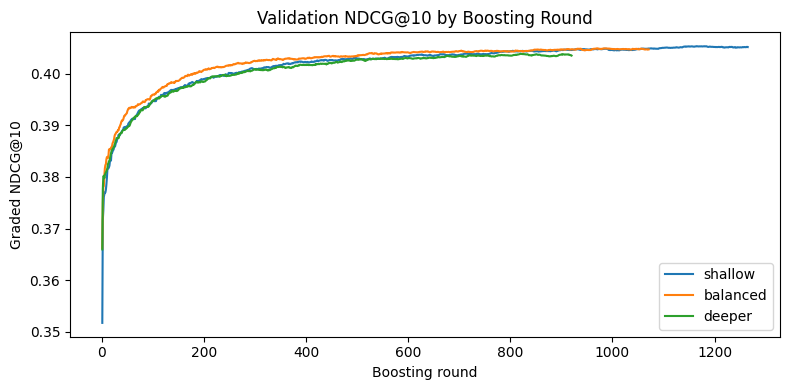

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
for trial in trial_df['trial']:
    p = RUN_DIR / f'{trial}_learning_curve.json'
    history = json.loads(p.read_text())
    scores = history.get('val', {}).get('ndcg@10', [])
    if scores:
        plt.plot(np.arange(1, len(scores) + 1), scores, label=trial)
plt.title('Validation NDCG@10 by Boosting Round')
plt.xlabel('Boosting round')
plt.ylabel('Graded NDCG@10')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import shutil
best_name = BEST_TRIAL['trial']
shutil.copy2(RUN_DIR / f'{best_name}_model.txt', RUN_DIR / 'best_model.txt')

PosixPath('/content/drive/MyDrive/BT4222 Final/JDSearch/model_artifacts/lightgbm_popularity_query_search/full/best_model.txt')

## 10. Export validation predictions from the selected model


In [ ]:
val_scores = BEST_MODEL.predict(DATA['val']['X'], num_threads=BASE_PARAMS['num_threads'])
assert len(val_scores) == DATA['val']['n_rows']
assert np.isfinite(val_scores).all(), 'Nonfinite validation predictions'
val_out = pd.DataFrame({
    'session_id': DATA['val']['session_id'],
    'wid': DATA['val']['wid'],
    'label': DATA['val']['y'],
    'score': val_scores.astype(np.float32),
})
val_out.to_parquet(RUN_DIR / 'val_predictions.parquet', index=False)

print('Validation predictions saved; next cell will calculate binary and graded NDCG on these same sessions.')

Validation predictions saved; next cell will calculate binary and graded NDCG on these same sessions.


## 11. Evaluate the same validation predictions using graded and binary NDCG@10

Graded NDCG uses `[0,1,3,7]` and binary NDCG uses `[0,1,1,1]`. Neither metric involves retraining the selected model. Scores from separate systems are directly comparable only if the candidate pools, held-out sessions, group aggregation and relevance definition are identical.


In [ ]:
def mean_ndcg_by_groups(scores, labels, groups, gains, k=10):
    scores = np.asarray(scores, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.int64)
    groups = np.asarray(groups, dtype=np.int64)
    gain_values = np.asarray(gains, dtype=np.float64)
    assert int(groups.sum()) == len(scores) == len(labels)
    discount = 1.0 / np.log2(np.arange(2, k + 2))
    offset, total, no_relevant_groups = 0, 0.0, 0
    for size in groups:
        end = offset + size
        gain = gain_values[labels[offset:end]]
        rank_score = scores[offset:end]
        cutoff = min(k, int(size))
        ideal = float(np.dot(np.sort(gain)[::-1][:cutoff], discount[:cutoff]))
        if ideal > 0:
            # Using stable score tie-breaking.
            idx = np.argsort(-rank_score, kind='stable')[:cutoff]
            dcg = float(np.dot(gain[idx], discount[:cutoff]))
            total += dcg / ideal
        else:
            no_relevant_groups += 1
        offset = end
    return float(total / len(groups)), int(no_relevant_groups)

validation_graded, no_pos = mean_ndcg_by_groups(
    val_scores, DATA['val']['y'], DATA['val']['group'], [0,1,3,7])
validation_binary, _ = mean_ndcg_by_groups(
    val_scores, DATA['val']['y'], DATA['val']['group'], [0,1,1,1])
validation_metrics = {
    'graded_ndcg_at_10': validation_graded,
    'binary_ndcg_at_10': validation_binary,
    'validation_sessions': int(len(DATA['val']['group'])),
    'validation_candidates': int(len(val_scores)),
    'all_zero_relevance_sessions': no_pos,
    'feature_set': 'selected_personalisation_query_popularity',
    'note': 'Metrics computed on validation ranking groups using the saved relevance labels.',
}
safe_output_path(RUN_DIR / 'comparable_validation_metrics.json').write_text(
    json.dumps(validation_metrics, indent=2))
print(pd.Series(validation_metrics).to_string())

graded_ndcg_at_10                                                       0.405354
binary_ndcg_at_10                                                       0.410916
validation_sessions                                                        17117
validation_candidates                                                    1536651
all_zero_relevance_sessions                                                    0
feature_set                            selected_personalisation_query_popularity
note                           Metrics computed on validation ranking groups ...


## 12. Feature importance


In [ ]:
importance = pd.DataFrame({
    'feature': FEATURES,
    'gain': BEST_MODEL.feature_importance(importance_type='gain'),
    'split_count': BEST_MODEL.feature_importance(importance_type='split'),
}).sort_values('gain', ascending=False)
importance.to_csv(RUN_DIR / 'feature_importance.csv', index=False)
display(importance)

,feature,gain,split_count
4,i2v_cos_mean,1.745228e+06,1398
21,item_ctr_train,8.314104e+05,2905
0,exact_wid_last_seen_days,5.326051e+05,848
3,title_cos_max,4.089711e+05,1132
1,shop_share,7.848737e+04,505
20,cate3_slate_share,6.715352e+04,1224
7,name_query_match,6.617335e+04,1156
2,shop_last_seen_days,6.441520e+04,677
5,last_i2v_cos,5.152706e+04,1069
22,cate3_ctr_train,3.127582e+04,1368


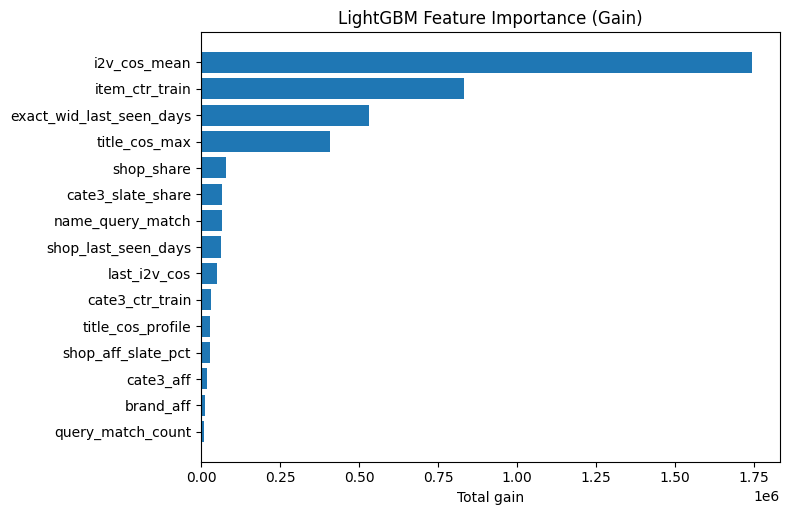

In [ ]:
top = importance.head(15).iloc[::-1]
plt.figure(figsize=(8, max(3, len(top)*0.35)))
plt.barh(top['feature'], top['gain'])
plt.title('LightGBM Feature Importance (Gain)')
plt.xlabel('Total gain')
plt.tight_layout()
plt.show()

## 13. Export selected model and evaluation handoff

The selected model, its exact input feature order, validation ranking scores and grouping information are written to this experiment's independent directory. The test feature cache was prepared earlier, but test observations are not used for training, feature selection or hyperparameter tuning. Test predictions are generated only after model finalisation.


In [ ]:
manifest = {
    'run': RUN_NAME, 'status': 'development' if FAST_DEV_MODE else 'full_training',
    'feature_set': 'selected_personalisation_query_popularity', 'features': FEATURES,
    'personalisation_features': PERSONALISATION_7, 'query_matching_features': QUERY_MATCH_7, 'additional_context_features': CONTEXT_7, 'popularity_features': POPULARITY_2,
    'seed': SEED, 'train_session_fraction': TRAIN_SESSION_FRACTION,
    'val_session_fraction': VAL_SESSION_FRACTION, 'objective': 'lambdarank',
    'metric_optimized': 'graded_NDCG@10', 'label_gain': LABEL_GAINS,
    'source_base_parquets': str(BASE_FEATURE_DIR),
    'source_query_checkpoint_pattern': '*candidate_features_checkpoint*.parquet',
    'query_token_source': str(RAW_USER_FILE), 'corrected_name_feature': 'distinct_query_product_name_token_overlap_count',
    'merged_feature_cache': str(MERGED_DIR),
    'source_split_csv': str(CANONICAL_SPLIT),
    'best_trial': BEST_TRIAL, 'lightgbm_version': lgb.__version__,
    'notes': 'Training and model selection use training/validation only; test predictions are optional and produced only after finalisation.'
}
manifest['test_scored_after_finalisation'] = (RUN_DIR / 'test_predictions.parquet').is_file()
safe_output_path(RUN_DIR / 'training_manifest.json').write_text(
    json.dumps(manifest, indent=2, default=str))
safe_output_path(RUN_DIR / 'feature_names.json').write_text(json.dumps(FEATURES, indent=2))
np.save(safe_output_path(RUN_DIR / 'val_groups.npy'), DATA['val']['group'])

required_handoff_files = [
    'best_model.txt','feature_names.json','training_manifest.json',
    'tuning_results.csv','feature_importance.csv','feature_quality.csv',
    'val_predictions.parquet','val_groups.npy', 'comparable_validation_metrics.json'
]
missing = [name for name in required_handoff_files if not (RUN_DIR / name).is_file()]
assert not missing, f'Output files missing: {missing}'
rows = pq.ParquetFile(RUN_DIR / 'val_predictions.parquet').metadata.num_rows
groups = np.load(RUN_DIR / 'val_groups.npy')
assert int(groups.sum()) == rows
assert set(['session_id','wid','label','score']) <= set(
    pq.ParquetFile(RUN_DIR / 'val_predictions.parquet').schema_arrow.names)
assert BEST_MODEL.num_trees() == int(BEST_TRIAL['best_iteration']),     'Best-model tree count does not match selected iteration'

handoff = {
    'run_name': RUN_NAME,
    'run_type': 'development_sample' if FAST_DEV_MODE else 'full',
    'model_file': 'best_model.txt',
    'predictions_file': 'val_predictions.parquet',
    'group_file': 'val_groups.npy',
    'feature_list_file': 'feature_names.json',
    'manifest_file': 'training_manifest.json',
    'validation_candidate_rows': int(rows),
    'validation_search_sessions': int(len(groups)),
    'best_validation_graded_ndcg_at_10': float(BEST_TRIAL['val_graded_NDCG@10']),
    'independently_computed_graded_ndcg_at_10': validation_graded,
    'binary_validation_ndcg_at_10': validation_binary,
    'test_scored': (RUN_DIR / 'test_predictions.parquet').exists(),
    'note': 'All artifacts are stored in the dedicated output directory.'
}
if handoff['test_scored']:
    handoff.update({
        'train_predictions_file': 'train_predictions.parquet',
        'test_predictions_file': 'test_predictions.parquet',
        'train_group_file': 'train_groups.npy',
        'test_group_file': 'test_groups.npy',
        'train_candidate_rows': int(pq.ParquetFile(RUN_DIR / 'train_predictions.parquet').metadata.num_rows),
        'test_candidate_rows': int(pq.ParquetFile(RUN_DIR / 'test_predictions.parquet').metadata.num_rows),
    })
safe_output_path(RUN_DIR / 'evaluation_handoff.json').write_text(json.dumps(handoff, indent=2))
# Test scoring is reserved for the optional final export after Section 14.
# This handoff can be rerun safely even if final predictions were already exported.
print('SUCCESS: LightGBM training handoff complete:', RUN_DIR)
print('Best trial:', BEST_TRIAL['trial'])
print('Best validation NDCG@10 (LightGBM):', BEST_TRIAL['val_graded_NDCG@10'])
print('Scored validation candidates:', f'{rows:,}', 'sessions:', f'{len(groups):,}')

SUCCESS: LightGBM training handoff complete: /content/drive/MyDrive/BT4222 Final/JDSearch/model_artifacts/lightgbm_popularity_query_search/full
Best trial: shallow
Best validation NDCG@10 (LightGBM): 0.4053536155038275
Scored validation candidates: 1,536,651 sessions: 17,117


## 14. Results, interpretation, and limitations

**Model selection:** Three LightGBM LambdaRank configurations were evaluated using the same 23 features and session-level training/validation split. The shallow configuration achieved the highest validation graded NDCG@10 of **0.4054**, compared with 0.4049 for the balanced model and 0.4039 for the deeper model. The selected model uses **15 leaves and 1,165 boosting iterations**. Although the more complex configurations achieved higher training scores, they did not improve validation performance.

**Feature importance:** `i2v_cos_mean`, `item_ctr_train`, `exact_wid_last_seen_days` and `title_cos_max` contributed the highest total gain. Conversely, `cate_name_1_query_match` recorded zero gain and zero splits, indicating that it was not used by the selected model. Feature importance reflects the fitted model's behaviour and does not independently establish the causal contribution of individual features.

**Interpretation:** The model produces relative ranking scores rather than calibrated click or purchase probabilities. The corrected `name_query_match` measures the number of distinct anonymised query tokens shared with a candidate's product name, while `query_match_count` counts matching product fields.

**Leakage and bias:** The item- and category-level engagement features were generated upstream using out-of-fold training statistics and training-only validation/test lookups. This notebook incorporates these precomputed features without recalculating them from interaction labels. The potentially problematic `position` feature, along with `item_impr_train` and `i2v_cos_max_slate_pct`, was excluded. Historical engagement features may also reflect product popularity and exposure rather than intrinsic relevance.

**Evaluation:** The selected model achieved independently calculated validation graded NDCG@10 of **0.405354** and binary NDCG@10 of **0.410916**, evaluated across **17,117 validation sessions**. The test set was not used for model selection or hyperparameter tuning. Train and test predictions were exported after finalisation for the group's shared evaluation.

**Reproducibility:** The completed `full/` directory contains the selected model, feature definitions, tuning results, feature importance, validation metrics and prediction outputs. Source datasets and previous model directories remain unchanged.

## 15. Final train/test prediction export

After selecting the best LightGBM configuration using validation results, `FINALIZE_TEST` was set to `True` to export predictions for the group's shared model evaluation.

The final export successfully generated:

- `train_predictions.parquet`: 12,279,873 candidates
- `test_predictions.parquet`: 1,531,525 candidates

Both files contain `session_id`, `wid`, `label` and `score`, with the corresponding group-size arrays saved separately.

The test data is used only for inference after model selection. No model retraining, feature selection or hyperparameter tuning is performed using test observations. Test NDCG@10 is not calculated in this notebook.

For future development runs, set `FINALIZE_TEST = False` and enable it only after finalising the model using training and validation data.

In [ ]:
# Final step: run once, only after features and settings have been finalised.
if not FINALIZE_TEST:
    print('Final train/test prediction export SKIPPED.')
    print('After finalising with validation, set FINALIZE_TEST = True in Section 2,')
    print('rerun the configuration cell, then run this cell without retraining.')
else:
    if FAST_DEV_MODE:
        raise AssertionError('Final predictions require FAST_DEV_MODE = False.')
    if TRAIN_SESSION_FRACTION != 1.0 or VAL_SESSION_FRACTION != 1.0:
        raise AssertionError('Final model must use complete train/validation session sets.')
    if BEST_MODEL.num_trees() != int(BEST_TRIAL['best_iteration']):
        raise AssertionError('Selected model and saved tuning results do not match.')
    if BEST_MODEL.feature_name() != FEATURES:
        raise AssertionError('Model feature names/order do not match FEATURES.')

    # Load only for inference: no fitting, feature selection, or tuning on test rows.
    DATA['test'] = load_grouped_split('test', FEATURES)
    expected = expected_split.reindex(DATA['test']['unique_session_id']).to_numpy()
    if not np.all(expected == 'test'):
        raise AssertionError('Test data does not match canonical user_split.csv.')
    assert set(DATA['test']['unique_session_id']).isdisjoint(
        set(DATA['train']['unique_session_id']))
    assert set(DATA['test']['unique_session_id']).isdisjoint(
        set(DATA['val']['unique_session_id']))

    for sp in ['train', 'test']:
        a = DATA[sp]
        scores = BEST_MODEL.predict(
            a['X'], num_threads=BASE_PARAMS['num_threads']
        ).astype(np.float32)
        if scores.shape[0] != a['n_rows'] or not np.isfinite(scores).all():
            raise AssertionError(f'{sp}: invalid prediction shape or nonfinite scores')
        pd.DataFrame({
            'session_id': a['session_id'],
            'wid': a['wid'],
            'label': a['y'],
            'score': scores,
        }).to_parquet(
            safe_output_path(RUN_DIR / f'{sp}_predictions.parquet'), index=False
        )
        np.save(safe_output_path(RUN_DIR / f'{sp}_groups.npy'), a['group'])
        saved_rows = pq.ParquetFile(RUN_DIR / f'{sp}_predictions.parquet').metadata.num_rows
        assert saved_rows == a['n_rows'] == int(a['group'].sum())
        print(f'Saved {sp} predictions: {saved_rows:,} candidates')
        del scores
        gc.collect()

    # Synchronise handoff information for the common results table.
    handoff_file = safe_output_path(RUN_DIR / 'evaluation_handoff.json')
    handoff = json.loads(handoff_file.read_text())
    handoff.update({
        'test_scored': True,
        'train_predictions_file': 'train_predictions.parquet',
        'test_predictions_file': 'test_predictions.parquet',
        'train_group_file': 'train_groups.npy',
        'test_group_file': 'test_groups.npy',
        'train_candidate_rows': int(DATA['train']['n_rows']),
        'test_candidate_rows': int(DATA['test']['n_rows']),
        'note': 'Model selected on validation only; train/test scores exported after finalisation.',
    })
    handoff_file.write_text(json.dumps(handoff, indent=2))
    manifest_file = safe_output_path(RUN_DIR / 'training_manifest.json')
    manifest = json.loads(manifest_file.read_text())
    manifest['test_scored_after_finalisation'] = True
    manifest_file.write_text(json.dumps(manifest, indent=2))
    print('Saved train and test predictions to', RUN_DIR)


Saved train predictions: 12,279,873 candidates
Saved test predictions: 1,531,525 candidates
Saved train and test predictions to /content/drive/MyDrive/BT4222 Final/JDSearch/model_artifacts/lightgbm_popularity_query_search/full
